In [2]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


ModuleNotFoundError: No module named 'notebook.auth'

In [2]:
from models.model2 import Model2
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm

/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [3]:
m2 = Model2()
m2.alpha = get_d2g_alpha(m2.V)

beta = TransitionPrior(m2.V)

beta.prefer_small_intervals(5,1)
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
m2.beta = beta.get_beta()
m2.build_model()


    nu ~ Dirichlet(<constant>)
     m ~ Categorical(nu)
   A_0 ~ Dirichlet(<constant>)
    pi ~ Dirichlet(<constant>)
   x_0 ~ Categorical(pi)
length ~ Poisson(40)
 x_t+1 ~ CustomDist_x_t+1(x_0, A_m, length)
   A_m ~ Deterministic(f(A_0, m))

In [4]:
samples = m2.prior_predict(1)
m2.show_melody(samples[0])

Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]


In [5]:
samples

[<xarray.Dataset> Size: 7kB
 Dimensions:      (chain: 1, draw: 1, nu_dim_0: 4, pi_dim_0: 18, A_0_dim_0: 18,
                   A_0_dim_1: 18, x_t+1_dim_0: 45, A_m_dim_0: 18, A_m_dim_1: 18)
 Coordinates:
   * chain        (chain) int64 8B 0
   * draw         (draw) int64 8B 0
   * nu_dim_0     (nu_dim_0) int64 32B 0 1 2 3
   * pi_dim_0     (pi_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
   * A_0_dim_0    (A_0_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
   * A_0_dim_1    (A_0_dim_1) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
   * x_t+1_dim_0  (x_t+1_dim_0) int64 360B 0 1 2 3 4 5 6 ... 38 39 40 41 42 43 44
   * A_m_dim_0    (A_m_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
   * A_m_dim_1    (A_m_dim_1) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
 Data variables:
     length       (chain, draw) int64 8B 45
     nu           (chain, draw, nu_dim_0) float64 32B 0.1562 0.1686 0.2471 0.4281
     x_0          (chain, draw) int64 8B 3


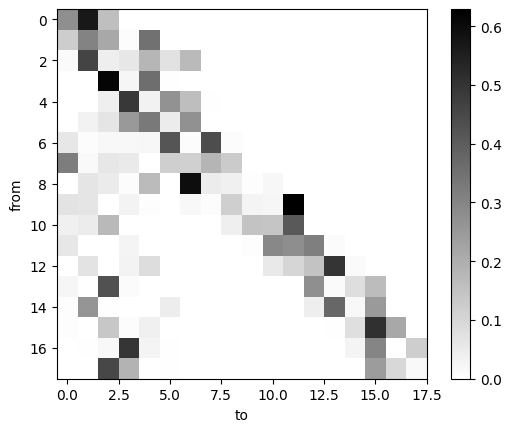

In [6]:
import models.model_utils as u

u.plot_heatmap(samples[0]["A_0"].sel(chain=0,draw=0).to_numpy())


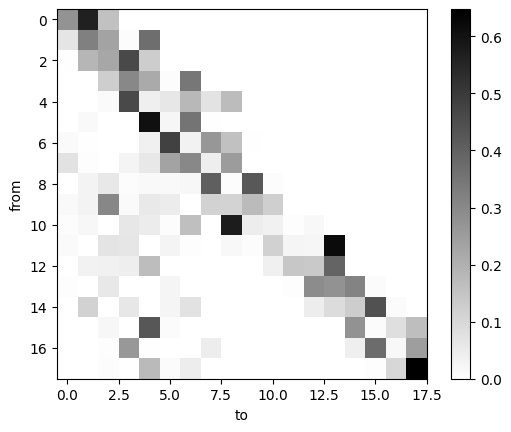

In [7]:

u.plot_heatmap(samples[0]["A_m"].sel(chain=0,draw=0).to_numpy())

In [18]:

import pickle
# Load Prepared Samples m1
with open("prior_predictive_model1.pkl", "rb") as f:
    m1 = pickle.load(f)

samples_m2 = m2.prior_predict(500)
models = {
 "M2": samples_m2,
 "Uninf": m1["Uninformative Prior"]
 }

Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]
Sampling: [A_

In [9]:
import importlib
import analysis.compare_dist_of_intv as compare
import pandas as pd
importlib.reload(compare)

Introits = pd.read_csv("data/Introits.csv")
PI = Introits["pitches"].dropna()


In [19]:
compare.plot_interval_histogram([models["Uninf"], models["M2"], PI], title=["Pitch Interval Distributions | Uninf", "M2", "Actual Introits"], normalize=True, save="visual/PID_uninf_m2.png")


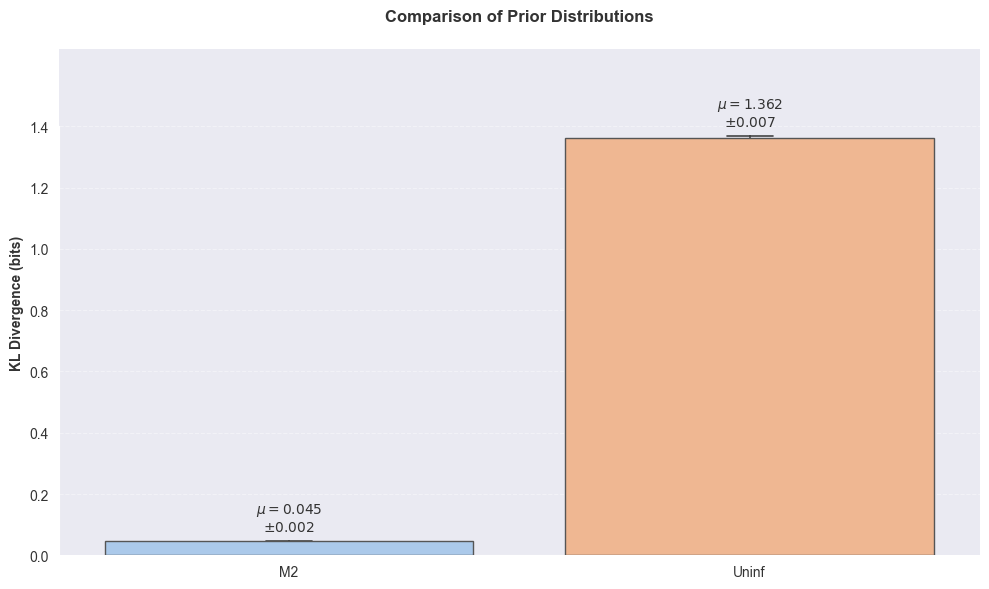

In [20]:
compare.plot_kl_with_context(PI, models, title="Comparison of Prior Distributions", save="visual/m2KLDiv.png")

In [21]:

PI


0       gkkklkjjkjlkkgkklkjihjjkjjjkjjghgghjjkmmmkjjjj...
1       gdfghhgfgghgfghihggjijkjjffhjiihjjjhihhjkjihjj...
2       dfgghfhjiihjjhgghgfgihgghggjhjjjghhhfhhihgghgg...
3       gkkklkjkijjlkkjkmmmmmnmkkmkmmmnmlkkkmonmmmmmmn...
4       defceddfegfgfggdddggghgffegfdedcdfefgdedccefff...
                              ...                        
3533                  dhhghihgfeeeghhghgfgfedcfghgfghgfee
3534    hhgfgfedcdffefdfgfedcefddfghghfefdcddcedffddfh...
3535    dhhgfgghhgfgfedefedccgghgfedcdefedccddcefgfddd...
3536       cdfedfghihgfggiighhigihffedddcfghgedefdcddhggh
3537                         dhhgfghgfgfeddggfgghgfefgfdd
Name: pitches, Length: 3537, dtype: str

In [10]:

#https://discourse.pymc.io/t/using-discretemarkovchain-with-batch-dimensions-and-data-of-different-lengths/16611/2
m2.fit_from_raw(PI[:10], 10, 50, chains=2)

Only 10 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.


[6 7 3 5 3 3 6 3 6 6] [[ 6  7  5 ...  5  3  9]
 [ 8  6  4 ...  6  5  9]
 [ 8  7  4 ...  6  6  9]
 ...
 [-1 -1 -1 ... -1 -1 -1]
 [-1 -1 -1 ... -1 -1 -1]
 [-1 -1 -1 ... -1 -1 -1]]


Multiprocess sampling (2 chains in 2 jobs)
CompoundStep
>NUTS: [nu, A_0, pi]
>CategoricalGibbsMetropolis: [m]


Output()

Sampling 2 chains for 50 tune and 10 draw iterations (100 + 20 draws total) took 51 seconds.
There were 17 divergences after tuning. Increase `target_accept` or reparameterize.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
The number of samples is too small to check convergence reliably.


Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [31]:
m2.trace.to_netcdf("samples/model2_samples_test.nc")


'samples/model2_samples1.nc'

In [11]:
import seaborn as sns
def plot_posterior_matrix(trace, matrix_name="A_m"):


        posterior_mean = trace.posterior[matrix_name].mean(dim=["chain", "draw"]).values
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(
            posterior_mean, 
            xticklabels=m2.alphabet, 
            yticklabels=m2.alphabet, 
            cmap="binary",
            annot=False
        )
        plt.title("Posterior Mean Transition Matrix")
        plt.xlabel("To Pitch")
        plt.ylabel("From Pitch")
        plt.show()

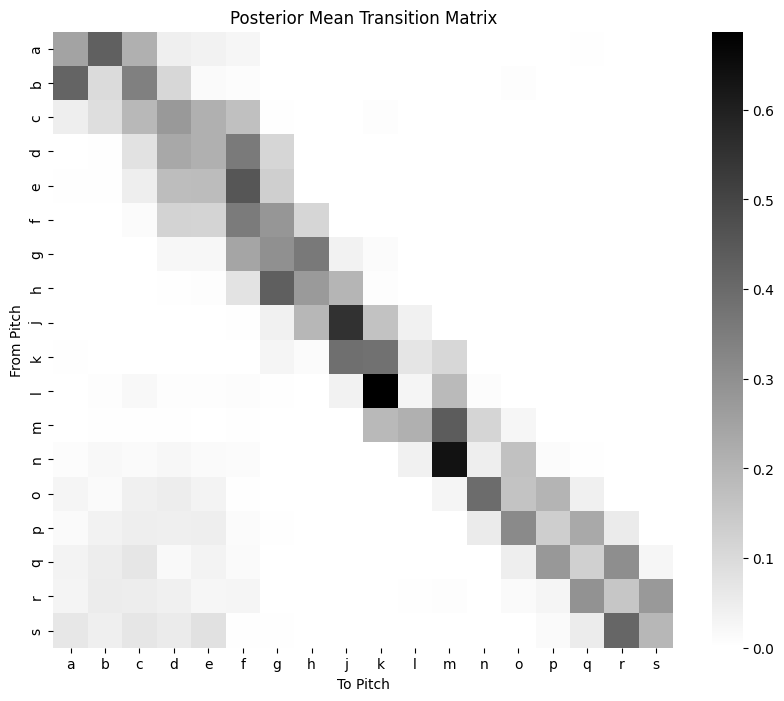

In [12]:
plot_posterior_matrix(m2.trace)

In [14]:
import analysis.visualise_posterior as vp

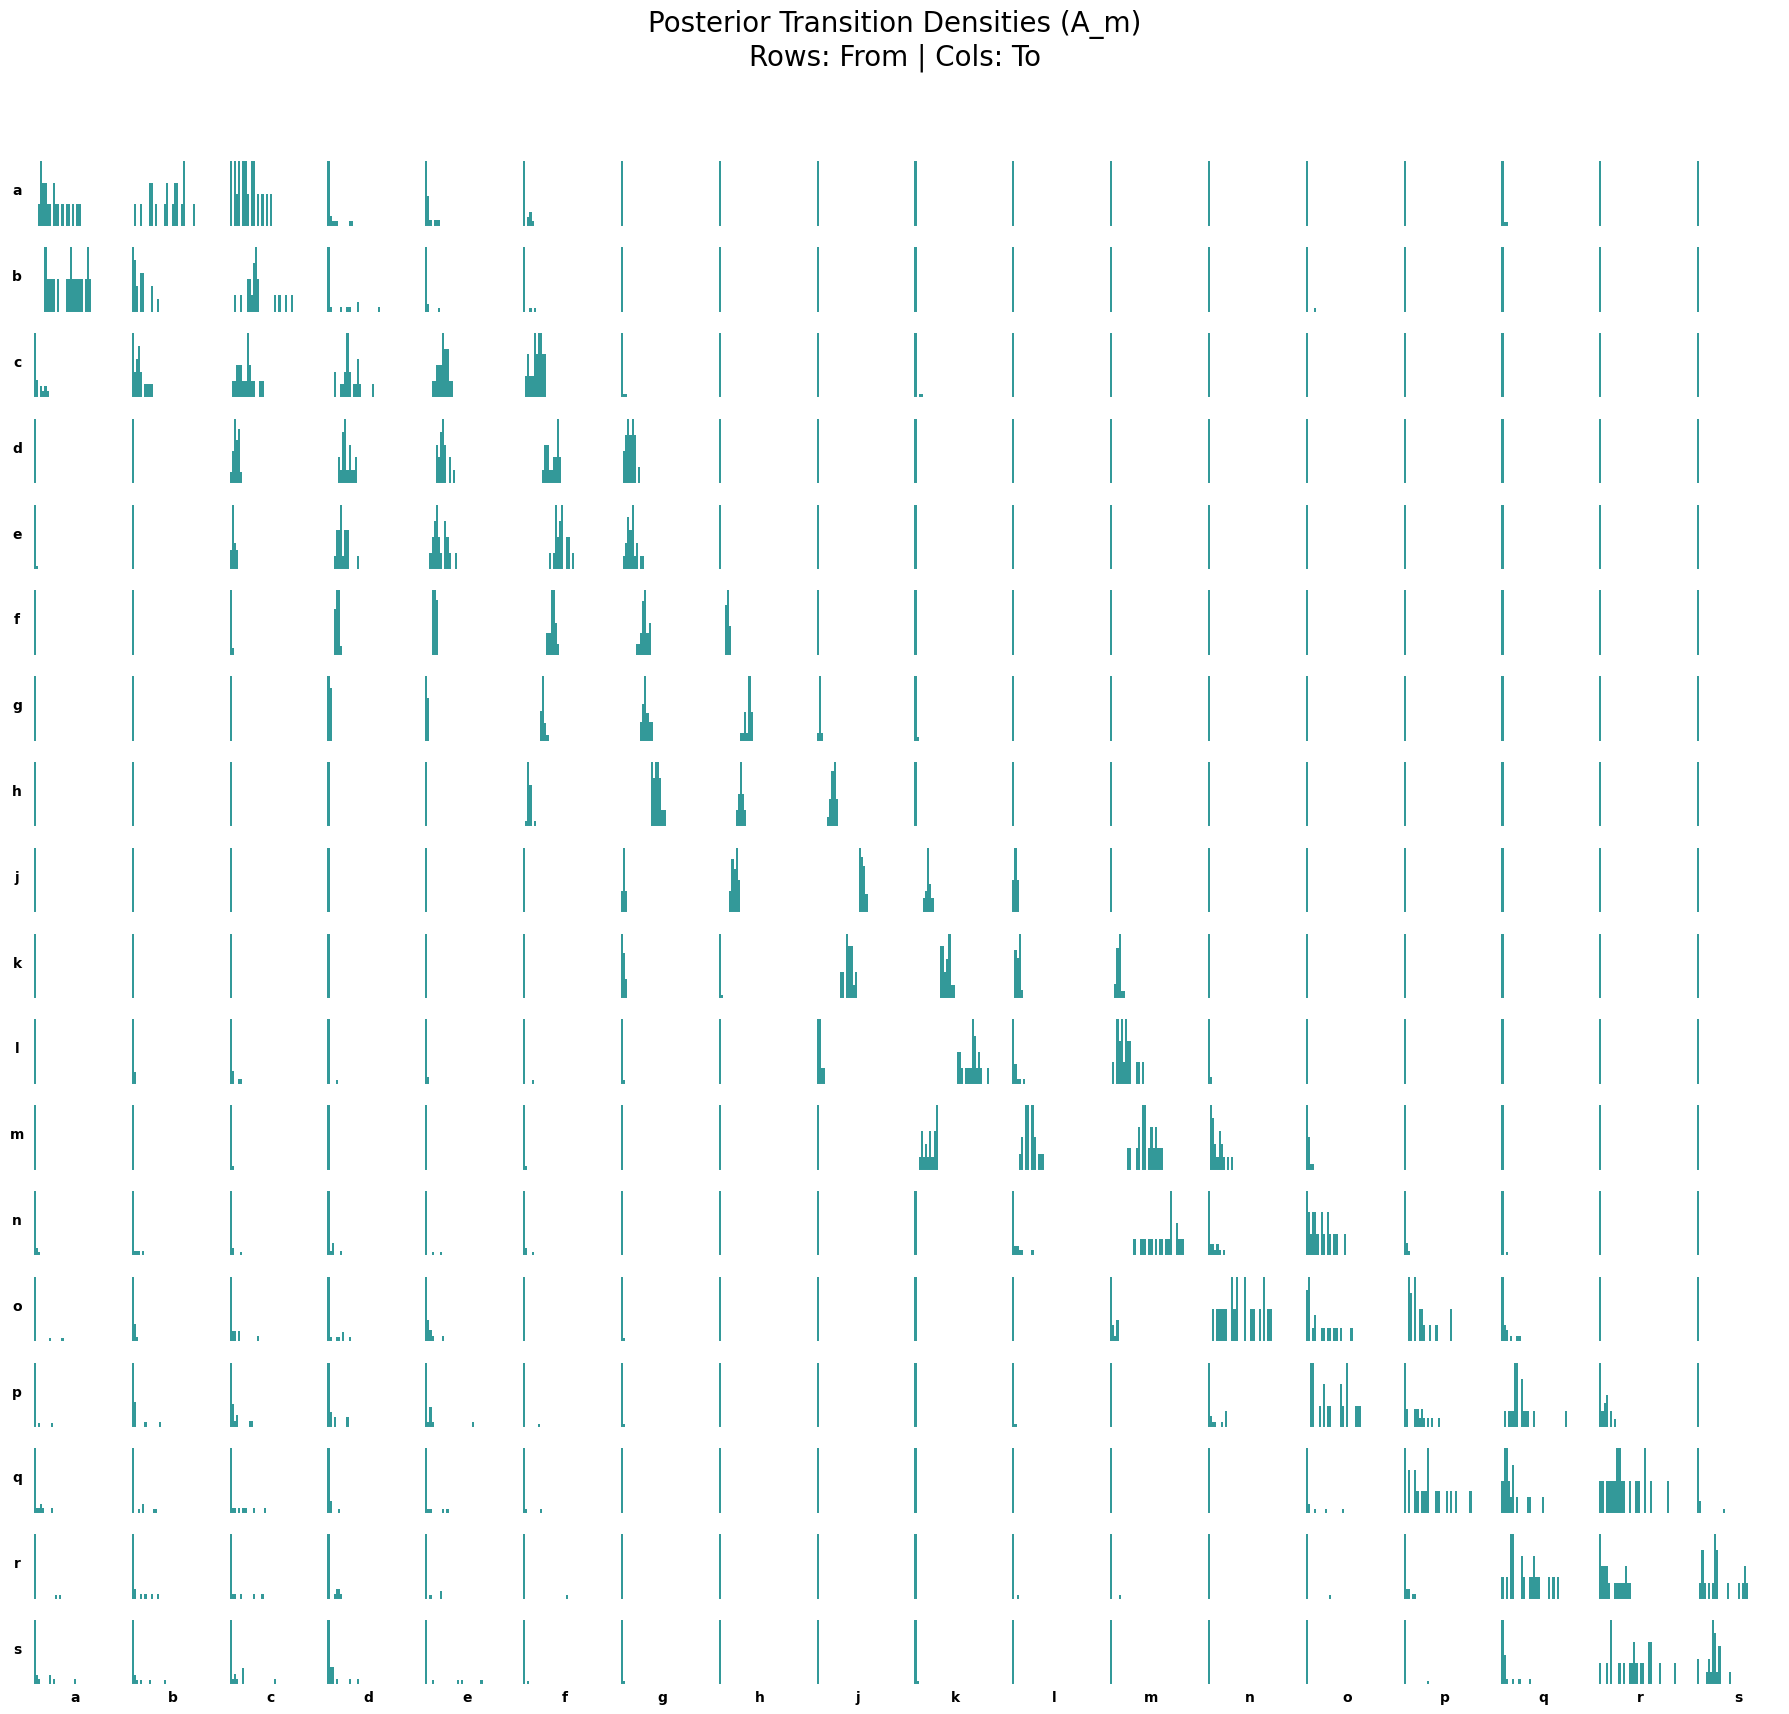

In [15]:
vp.plot_transition_matrix_posterior(m2.trace, "A_m")